# Clasificación: aprobación en Electricidad y Magnetismo

### Pregunta de investigación
**¿Hay carreras (como Mecatrónica, con formación más eléctrica) que aprueban significativamente más que otras (como Civil)?**

El objetivo es predecir `Aprobado` a partir de variables disponibles para el estudiante/curso, especialmente `Carrera`, además de `Anho` y `Semestre`.

### Criterio metodológico importante
- `Aprobado` es la variable objetivo (`y`).
- `Carrera` es la variable de interés principal.
- `Anho` y `Semestre` permiten controlar diferencias entre periodos.
- **`Nota.Final` NO se utiliza como predictor**, porque está directamente relacionada con la aprobación y produciría fuga de información.
- El análisis descriptivo por carrera será tan importante como las métricas de clasificación, porque la pregunta busca comparar tasas de aprobación entre carreras.

In [62]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay,
    confusion_matrix
)

import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.3f}'.format)

## 1. Cargar el dataset

In [63]:
ARCHIVO = r'D:\\Materiales\\IA\\cursoIA2026\\Semana_03\\Ejercicio\\datos\\reglamentonuevo\\datos_electricidad_magnetismo.csv'

df = pd.read_csv(ARCHIVO)

print(f'✅ Registros cargados: {len(df):,}')
print(f'📌 Columnas: {len(df.columns)}')

display(df.head())

✅ Registros cargados: 1,515
📌 Columnas: 11


,ALUMNO_ID,Carrera,Asignatura,Anho,Semestre,Nota.Final,Aprobado,Aprobado_binario,Cod.Curso,Cod.Car.Sec,Archivo_Origen
0,FIUNA_ALUMNO_000452,CIV,ELECTRICIDAD Y MAGNETISMO,2024,2,NaN,N,0,3,CIV-PLS23,rendimiento_año_2024_ciclo_2_anon.xlsx
1,FIUNA_ALUMNO_012722,CIV,ELECTRICIDAD Y MAGNETISMO,2024,2,NaN,N,0,3,CIV-PLS23,rendimiento_año_2024_ciclo_2_anon.xlsx
2,FIUNA_ALUMNO_003750,MEC,ELECTRICIDAD Y MAGNETISMO,2024,2,NaN,N,0,3,MEC-PLS23,rendimiento_año_2024_ciclo_2_anon.xlsx
3,FIUNA_ALUMNO_004171,MEC,ELECTRICIDAD Y MAGNETISMO,2024,2,NaN,N,0,3,MEC-PLS23,rendimiento_año_2024_ciclo_2_anon.xlsx
4,FIUNA_ALUMNO_005168,IND,ELECTRICIDAD Y MAGNETISMO,2024,2,NaN,N,0,3,IND-PLS23,rendimiento_año_2024_ciclo_2_anon.xlsx


## 2. Verificar carreras disponibles

In [64]:
print('Carreras disponibles:')
display(df['Carrera'].value_counts(dropna=False))

print('\nValores de Aprobado:')
display(df['Aprobado'].value_counts(dropna=False))

Carreras disponibles:


Carrera
CIV    715
ELE    290
MCT    170
IND    152
CGF     74
MEC     68
ECA     46
Name: count, dtype: int64


Valores de Aprobado:


Aprobado
N    1195
S     320
Name: count, dtype: int64

## 3. Filtrar únicamente Civil (CIV) y Mecatrónica (MCT)

In [65]:
df['Carrera'] = df['Carrera'].astype(str).str.strip().str.upper()
df['Aprobado'] = df['Aprobado'].astype(str).str.strip().str.upper()

df_comparacion = df[df['Carrera'].isin(['CIV', 'MCT'])].copy()

if df_comparacion.empty:
    raise ValueError('No se encontraron registros para CIV y MCT.')

print(f'✅ Registros CIV + MCT: {len(df_comparacion):,}')
print('\nDistribución por carrera:')
display(df_comparacion['Carrera'].value_counts())

✅ Registros CIV + MCT: 885

Distribución por carrera:


Carrera
CIV    715
MCT    170
Name: count, dtype: int64

## 4. Preparar la variable objetivo

In [66]:
df_comparacion['Aprobado_binario'] = df_comparacion['Aprobado'].map({'S': 1, 'N': 0})
df_comparacion['Anho'] = pd.to_numeric(df_comparacion['Anho'], errors='coerce')
df_comparacion['Semestre'] = pd.to_numeric(df_comparacion['Semestre'], errors='coerce')

df_comparacion = df_comparacion.dropna(
    subset=['Carrera', 'Anho', 'Semestre', 'Aprobado_binario']
).copy()

print(f'Registros válidos: {len(df_comparacion):,}')
print(f'Proporción de aprobados: {df_comparacion["Aprobado_binario"].mean():.2%}')

Registros válidos: 885
Proporción de aprobados: 22.82%


## 5. Comparación descriptiva CIV vs MCT

In [67]:
tabla_carrera = (
    df_comparacion.groupby('Carrera')
    .agg(
        Total=('Aprobado_binario', 'size'),
        Aprobados=('Aprobado_binario', 'sum'),
        No_Aprobados=('Aprobado_binario', lambda x: (x == 0).sum()),
        Tasa_Aprobacion=('Aprobado_binario', 'mean')
    )
    .reset_index()
)

tabla_carrera['Tasa_Aprobacion'] *= 100
display(tabla_carrera)

,Carrera,Total,Aprobados,No_Aprobados,Tasa_Aprobacion
0,CIV,715,154,561,21.538
1,MCT,170,48,122,28.235


## 6. Diferencia de tasa de aprobación

In [68]:
tasas = tabla_carrera.set_index('Carrera')['Tasa_Aprobacion']

if 'CIV' in tasas.index and 'MCT' in tasas.index:
    diferencia = tasas['MCT'] - tasas['CIV']
    print(f'Tasa CIV: {tasas["CIV"]:.2f}%')
    print(f'Tasa MCT: {tasas["MCT"]:.2f}%')
    print(f'Diferencia MCT - CIV: {diferencia:.2f} puntos porcentuales')
else:
    print('⚠️ No están presentes ambas carreras.')

Tasa CIV: 21.54%
Tasa MCT: 28.24%
Diferencia MCT - CIV: 6.70 puntos porcentuales


## 7. Visualización de las tasas de aprobación

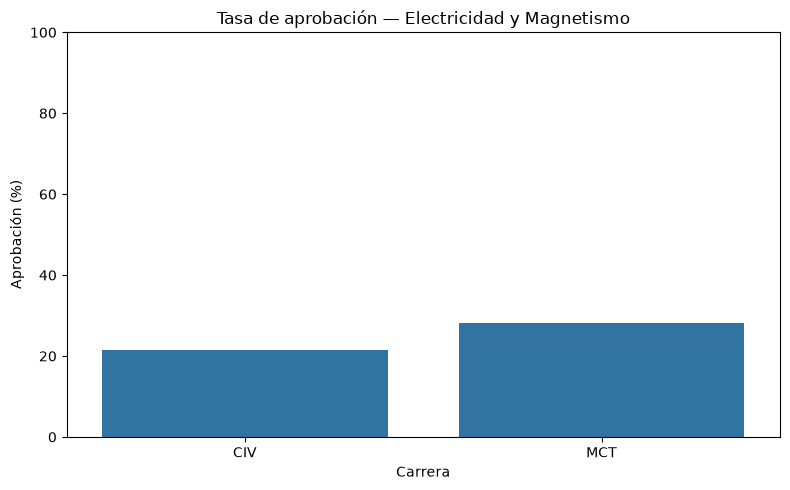

In [69]:
plt.figure(figsize=(8, 5))
sns.barplot(data=tabla_carrera, x='Carrera', y='Tasa_Aprobacion')
plt.ylim(0, 100)
plt.title('Tasa de aprobación — Electricidad y Magnetismo')
plt.xlabel('Carrera')
plt.ylabel('Aprobación (%)')
plt.tight_layout()
plt.show()

## 8. Aprobación por carrera y año

In [70]:
tabla_anho = (
    df_comparacion.groupby(['Anho', 'Carrera'])
    .agg(
        Total=('Aprobado_binario', 'size'),
        Aprobados=('Aprobado_binario', 'sum'),
        Tasa_Aprobacion=('Aprobado_binario', 'mean')
    )
    .reset_index()
)
tabla_anho['Tasa_Aprobacion'] *= 100
display(tabla_anho.sort_values(['Anho', 'Carrera']))

,Anho,Carrera,Total,Aprobados,Tasa_Aprobacion
0,2024,CIV,285,50,17.544
1,2024,MCT,76,16,21.053
2,2025,CIV,430,104,24.186
3,2025,MCT,94,32,34.043


## 9. Preparar X e y para los modelos

In [71]:
features = ['Carrera', 'Anho', 'Semestre']

X = df_comparacion[features].copy()
y = df_comparacion['Aprobado_binario'].copy()

print('Variables predictoras:')
print(features)
print('\nVariable objetivo: Aprobado_binario')

Variables predictoras:
['Carrera', 'Anho', 'Semestre']

Variable objetivo: Aprobado_binario


## 10. División entrenamiento/prueba y codificación de Carrera

In [72]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

preprocesador = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(drop=None, handle_unknown='ignore'), ['Carrera']),
        ('num', 'passthrough', ['Anho', 'Semestre'])
    ]
)

print(f'Train: {len(X_train):,}')
print(f'Test: {len(X_test):,}')

Train: 619
Test: 266


## 11. Entrenar Decision Tree, Random Forest y Extra Trees

In [73]:
modelos = {
    'Decision Tree': DecisionTreeClassifier(
        max_depth=3,
        min_samples_leaf=10,
        class_weight='balanced',
        random_state=42
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=300,
        max_depth=4,
        min_samples_leaf=5,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ),
    'Extra Trees': ExtraTreesClassifier(
        n_estimators=300,
        max_depth=4,
        min_samples_leaf=5,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    )
}

pipelines = {}

for nombre, modelo in modelos.items():
    pipelines[nombre] = Pipeline([
        ('preprocesamiento', preprocesador),
        ('modelo', modelo)
    ])
    pipelines[nombre].fit(X_train, y_train)
    print(f'✅ {nombre} entrenado')

✅ Decision Tree entrenado
✅ Random Forest entrenado
✅ Extra Trees entrenado


## 12. Evaluar los tres modelos

In [74]:
resultados = []

for nombre, pipeline in pipelines.items():
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    resultados.append({
        'Modelo': nombre,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1': f1_score(y_test, y_pred, zero_division=0),
        'AUC': roc_auc_score(y_test, y_prob)
    })

tabla_resultados = pd.DataFrame(resultados).sort_values('AUC', ascending=False)
display(tabla_resultados)

,Modelo,Accuracy,Precision,Recall,F1,AUC
0,Decision Tree,0.451,0.226,0.574,0.324,0.507
1,Random Forest,0.451,0.226,0.574,0.324,0.507
2,Extra Trees,0.451,0.226,0.574,0.324,0.507


## 13. Evaluar el mejor modelo

🏆 Mejor modelo: Decision Tree

Reporte de clasificación:
              precision    recall  f1-score   support

 No aprobado       0.77      0.41      0.54       205
    Aprobado       0.23      0.57      0.32        61

    accuracy                           0.45       266
   macro avg       0.50      0.49      0.43       266
weighted avg       0.64      0.45      0.49       266



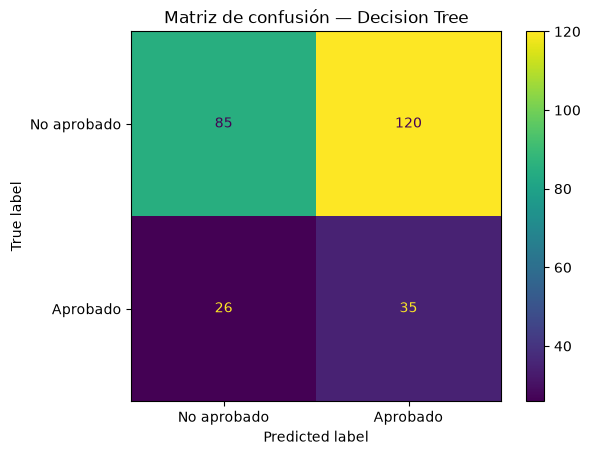

In [75]:
mejor_nombre = tabla_resultados.iloc[0]['Modelo']
mejor_modelo = pipelines[mejor_nombre]

y_pred_mejor = mejor_modelo.predict(X_test)
y_prob_mejor = mejor_modelo.predict_proba(X_test)[:, 1]

print(f'🏆 Mejor modelo: {mejor_nombre}')
print('\nReporte de clasificación:')
print(classification_report(
    y_test,
    y_pred_mejor,
    target_names=['No aprobado', 'Aprobado'],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_mejor,
    display_labels=['No aprobado', 'Aprobado']
)
plt.title(f'Matriz de confusión — {mejor_nombre}')
plt.show()

## 14. Importancia de variables del árbol

In [76]:
modelo_arbol = mejor_modelo.named_steps['modelo']
pre = mejor_modelo.named_steps['preprocesamiento']

nombres_features = pre.get_feature_names_out()

importancias = pd.DataFrame({
    'Variable': nombres_features,
    'Importancia': modelo_arbol.feature_importances_
}).sort_values('Importancia', ascending=False)

display(importancias)

,Variable,Importancia
2,num__Anho,0.768
0,cat__Carrera_CIV,0.232
1,cat__Carrera_MCT,0.000
3,num__Semestre,0.000


## 15. Importancia agrupada por variable original

,Variable_Original,Importancia
0,Anho,0.768
1,Carrera,0.232
2,Semestre,0.000


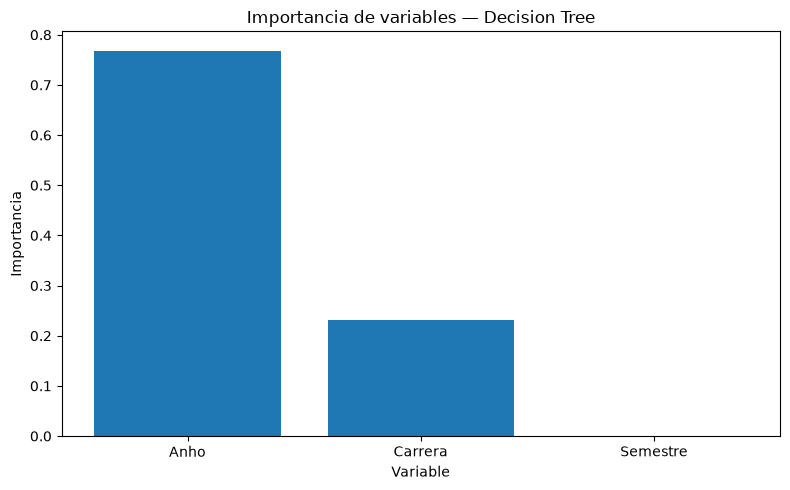

In [77]:
importancias_agrupadas = importancias.copy()

importancias_agrupadas['Variable_Original'] = importancias_agrupadas['Variable'].copy()

importancias_agrupadas.loc[
    importancias_agrupadas['Variable'].str.startswith('cat__Carrera'),
    'Variable_Original'
] = 'Carrera'

importancias_agrupadas['Variable_Original'] = (
    importancias_agrupadas['Variable_Original']
    .str.replace('num__', '', regex=False)
)

importancias_agrupadas = (
    importancias_agrupadas
    .groupby('Variable_Original', as_index=False)['Importancia']
    .sum()
    .sort_values('Importancia', ascending=False)
)

display(importancias_agrupadas)

plt.figure(figsize=(8, 5))
plt.bar(importancias_agrupadas['Variable_Original'], importancias_agrupadas['Importancia'])
plt.xlabel('Variable')
plt.ylabel('Importancia')
plt.title(f'Importancia de variables — {mejor_nombre}')
plt.tight_layout()
plt.show()

## 16. Comparar el comportamiento CIV vs MCT dentro del conjunto de prueba

In [78]:
pred_test = X_test.copy()
pred_test['Real'] = y_test.values
pred_test['Prediccion'] = y_pred_mejor
pred_test['Prob_Aprobar'] = y_prob_mejor

tabla_test_carrera = (
    pred_test.groupby('Carrera')
    .agg(
        Casos=('Real', 'size'),
        Tasa_Real=('Real', 'mean'),
        Tasa_Predicha=('Prediccion', 'mean'),
        Probabilidad_Media=('Prob_Aprobar', 'mean')
    )
    .reset_index()
)

for col in ['Tasa_Real', 'Tasa_Predicha', 'Probabilidad_Media']:
    tabla_test_carrera[col] *= 100

display(tabla_test_carrera)

,Carrera,Casos,Tasa_Real,Tasa_Predicha,Probabilidad_Media
0,CIV,211,21.801,59.242,47.307
1,MCT,55,27.273,54.545,55.694
